In [1]:
from google.colab import drive
drive.mount('/content/drive')
%cd /content/drive/MyDrive/Projects/karate-kumite-performance-profiles-lab/

Mounted at /content/drive
/content/drive/MyDrive/Projects/karate-kumite-performance-profiles-lab


In [51]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from scipy.cluster.hierarchy import linkage, fcluster
from sklearn.cluster import KMeans, DBSCAN
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score,
    adjusted_rand_score, normalized_mutual_info_score,
)

RNG_SEED = 0
np.random.seed(RNG_SEED)

DATA_DIR = Path("data")
OUTPUT_DIR = Path("outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FILES = {
    "Female-42kg": DATA_DIR / "female_42kg.csv",
    "Female-47kg": DATA_DIR / "female_47kg.csv",
    "Female-54kg": DATA_DIR / "female_54kg.csv",
}

P0_FEATURES = ["yuko", "waza_ari", "ippon", "attack", "defend",
               "longest_point_in_sec", "fastest_point_in_sec"]

TIMING_FEATURES    = ["longest_point_in_sec", "fastest_point_in_sec"]
NONTIMING_FEATURES = [c for c in P0_FEATURES if c not in TIMING_FEATURES]

S1_FEATURES = P0_FEATURES + ["match_attack", "match_defend"]
S2_FEATURES = P0_FEATURES + ["state_numeric", "hantei", "point_diff"]
STRUCTURAL_ZERO_FEATURES = ["yuko", "longest_point_in_sec", "fastest_point_in_sec"]


#Data

In [3]:
# @title [function]-Load Data
# Load data function

def _synthetic_weight_class(seed, n_matches=19):

    rng = np.random.default_rng(seed)
    n = n_matches * 2
    m = np.repeat(np.arange(n_matches), 2)
    df = pd.DataFrame({
        "weight_class": "Female-Demo",
        "stage": "stage-1",
        "match": m,
        "name": [f"athlete_{i}" for i in range(n)],
        "state": rng.choice(["win", "lose"], size=n),
        "hantei": 0,
        "yuko": rng.poisson(1.2, size=n) * rng.choice([0, 1], size=n, p=[0.4, 0.6]),
        "waza_ari": rng.poisson(0.2, size=n),
        "ippon": rng.poisson(0.1, size=n),
        "attack": rng.poisson(8, size=n),
        "defend": rng.poisson(6, size=n),
        "longest_point_in_sec": rng.uniform(0, 90, size=n) * rng.choice([0, 1], size=n, p=[0.3, 0.7]),
        "fastest_point_in_sec": rng.uniform(0, 40, size=n) * rng.choice([0, 1], size=n, p=[0.3, 0.7]),
        "match_attack": rng.poisson(16, size=n),
        "match_defend": rng.poisson(12, size=n),
        "point_diff": rng.integers(-8, 8, size=n),
    })
    return df


def load_weight_class(name, filepath):
    if filepath.exists():
        df = pd.read_csv(filepath, sep=";")
        df = df.dropna(how="all").reset_index(drop=True)
        df.columns = df.columns.str.strip()
    else:
        print(f"[demo mode] {filepath} not found -- using synthetic stand-in for {name}")
        df = _synthetic_weight_class(seed=hash(name) % (2**31))
    df["state_numeric"] = df["state"].str.lower().map({"win": 1, "lose": 0})
    return df

In [4]:
# @title [implementation]-Load Data
raw_data = {name: load_weight_class(name, path) for name, path in FILES.items()}

for name, df in raw_data.items():
  print("Data: ", name, " with ", df.shape[0], " samples and ", df.shape[1], " features")

print("")
print("Features: ")
for cfg_name, feats in [("P0", P0_FEATURES), ("S1", S1_FEATURES), ("S2", S2_FEATURES)]:
  print(cfg_name, ": ", feats)

print("")
print("Samples [P0 features only]: ")
display(raw_data["Female-42kg"][["name"] + P0_FEATURES].head(3))

Data:  Female-42kg  with  38  samples and  21  features
Data:  Female-47kg  with  38  samples and  21  features
Data:  Female-54kg  with  38  samples and  21  features

Features: 
P0 :  ['yuko', 'waza_ari', 'ippon', 'attack', 'defend', 'longest_point_in_sec', 'fastest_point_in_sec']
S1 :  ['yuko', 'waza_ari', 'ippon', 'attack', 'defend', 'longest_point_in_sec', 'fastest_point_in_sec', 'match_attack', 'match_defend']
S2 :  ['yuko', 'waza_ari', 'ippon', 'attack', 'defend', 'longest_point_in_sec', 'fastest_point_in_sec', 'state_numeric', 'hantei', 'point_diff']

Samples [P0 features only]: 


,name,yuko,waza_ari,ippon,attack,defend,longest_point_in_sec,fastest_point_in_sec
0,S. Mosleh,2,0,2,4,2,6,2
1,Vinogradova,0,0,0,4,1,0,0
2,Abellanosa,0,0,0,2,4,0,0


## EDA on P0 Feature

In [5]:
display(raw_data["Female-42kg"][P0_FEATURES].describe())
#display(raw_data["Female-47kg"][P0_FEATURES].describe())
#display(raw_data["Female-54kg"][P0_FEATURES].describe())

,yuko,waza_ari,ippon,attack,defend,longest_point_in_sec,fastest_point_in_sec
count,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000,38.000000
mean,2.684211,0.105263,0.315789,5.500000,3.552632,3.631579,2.078947
std,2.692384,0.311012,0.701553,2.152936,1.781244,3.026201,1.666548
min,0.000000,0.000000,0.000000,2.000000,1.000000,0.000000,0.000000
25%,0.000000,0.000000,0.000000,4.000000,2.000000,0.000000,0.000000
50%,2.500000,0.000000,0.000000,5.000000,3.500000,5.000000,3.000000
75%,4.750000,0.000000,0.000000,6.000000,5.000000,6.000000,3.000000
max,9.000000,1.000000,2.000000,11.000000,7.000000,8.000000,4.000000


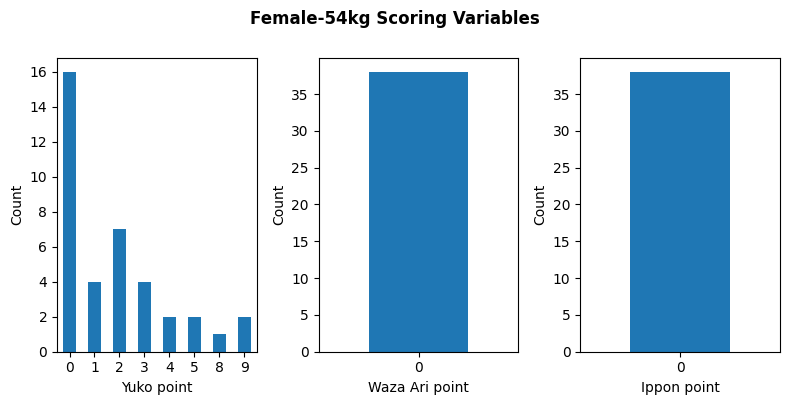

In [44]:
# @title Scoring Variables Distribution { run: "auto" }
# @markdown Here the distribution of Scoring Variables for certain weight class (wc):

wc = "Female-54kg" #@param ["Female-42kg", "Female-47kg", "Female-54kg"]
fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(8, 4))
fig.suptitle(wc+" Scoring Variables", fontsize=12, fontweight='bold', y=1)

yuko_distribution = raw_data[wc][P0_FEATURES].yuko.value_counts().sort_index()
yuko_distribution.plot(kind="bar", rot=0, ax=axes[0])

axes[0].set_xlabel("Yuko point")
axes[0].set_ylabel("Count")

waza_ari_distribution = raw_data[wc][P0_FEATURES].waza_ari.value_counts().sort_index()
waza_ari_distribution.plot(kind="bar", rot=0, ax=axes[1])

axes[1].set_xlabel("Waza Ari point")
axes[1].set_ylabel("Count")

ippon_distribution = raw_data[wc][P0_FEATURES].ippon.value_counts().sort_index()
ippon_distribution.plot(kind="bar", rot=0, ax=axes[2])

axes[2].set_xlabel("Ippon point")
axes[2].set_ylabel("Count")

plt.tight_layout(rect=[0, 0, 1, 1])
plt.show()

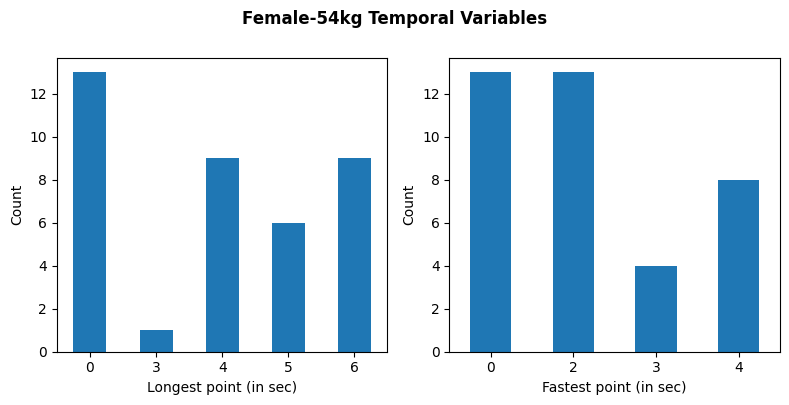

In [38]:
# @title Temporal Variables Distribution { run: "auto" }
# @markdown Here the distribution of Temporal/Timing Variables for certain weight class (wc):

# 1. Simple text input box
wc = "Female-54kg" #@param ["Female-42kg", "Female-47kg", "Female-54kg"]
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(8, 4))
fig.suptitle(wc+" Temporal Variables", fontsize=12, fontweight='bold', y=1)

long_point_distribution = raw_data[wc][P0_FEATURES].longest_point_in_sec.value_counts().sort_index()
long_point_distribution.plot(kind="bar", rot=0, ax=axes[0])

axes[0].set_ylabel("Count")
axes[0].set_xlabel("Longest point (in sec)")

fast_point_distribution = raw_data[wc][P0_FEATURES].fastest_point_in_sec.value_counts().sort_index()
fast_point_distribution.plot(kind="bar", rot=0, ax=axes[1])

axes[1].set_xlabel("Fastest point (in sec)")
axes[1].set_ylabel("Count")

plt.tight_layout(rect=[0, 0, 1, 1])
plt.show()

#Pre-processing

##Feature Selection

In [45]:
# @title
def build_matrix(df, feature_list):
    X_raw     = df[feature_list].apply(pd.to_numeric, errors="raise")
    variances = X_raw.var(ddof=0)
    zero_var  = variances[variances == 0].index.tolist()
    retained  = [c for c in feature_list if c not in zero_var]
    X_final   = X_raw[retained]
    scaler    = StandardScaler()
    X_scaled  = scaler.fit_transform(X_final)
    return X_scaled, retained, zero_var

In [53]:
def build_two_part_matrix(df):
    """
    Two-part encoding of the timing variables:
      Part 1: timing_event = 1 if a scoring-time event was recorded, else 0
      Part 2: each timing variable z-scored using SCORERS ONLY;
              non-scorers set to 0 (= the average scorer)
    Zero-variance removal is reused from build_matrix().
    """
    timing = df[TIMING_FEATURES].apply(pd.to_numeric, errors="raise")
    scored = (timing > 0).any(axis=1).to_numpy()

    # Part 1: non-timing features + event indicator (goes through build_matrix)
    df_tmp = df.copy()
    df_tmp["timing_event"] = scored.astype(float)
    X_part1, retained, dropped = build_matrix(
        df_tmp, NONTIMING_FEATURES + ["timing_event"]
    )

    # Part 2: conditional durations
    cond_cols, cond_names = [], []
    for c in TIMING_FEATURES:
        s = timing.loc[scored, c]
        if s.std(ddof=0) == 0:              # constant among scorers -> drop
            dropped.append(c + "_cond")
            continue
        z = ((timing[c] - s.mean()) / s.std(ddof=0)).to_numpy(dtype=float, copy=True)
        z[~scored] = 0.0
        cond_cols.append(z)
        cond_names.append(c + "_cond")

    X_scaled = np.column_stack([X_part1] + cond_cols)
    return X_scaled, retained + cond_names, dropped

In [54]:
prepared = {}
for wc, df in raw_data.items():
    prepared[wc] = {}
    scored   = (df[TIMING_FEATURES] > 0).any(axis=1).to_numpy()
    all_rows = np.ones(len(df), dtype=bool)

    # Original configurations
    for cfg_name, feats in [("P0", P0_FEATURES), ("S1", S1_FEATURES), ("S2", S2_FEATURES)]:
        Xs, retained, dropped = build_matrix(df, feats)
        prepared[wc][cfg_name] = {"X": Xs, "features": retained, "dropped": dropped, "rows": all_rows}
        print(wc, cfg_name, "->", Xs.shape, "dropped:", dropped)

    # TP: two-part encoding
    Xs, retained, dropped = build_two_part_matrix(df)
    prepared[wc]["TP"] = {"X": Xs, "features": retained, "dropped": dropped, "rows": all_rows}
    print(wc, "TP", "->", Xs.shape, "dropped:", dropped)

    # NT: no timing variables
    Xs, retained, dropped = build_matrix(df, NONTIMING_FEATURES)
    prepared[wc]["NT"] = {"X": Xs, "features": retained, "dropped": dropped, "rows": all_rows}
    print(wc, "NT", "->", Xs.shape, "dropped:", dropped)

    # SO: scorers only (fewer rows)
    df_so = df.loc[scored].reset_index(drop=True)
    Xs, retained, dropped = build_matrix(df_so, P0_FEATURES)
    prepared[wc]["SO"] = {"X": Xs, "features": retained, "dropped": dropped, "rows": scored}
    print(wc, "SO", "->", Xs.shape, "dropped:", dropped)
    print("")

Female-42kg P0 -> (38, 7) dropped: []
Female-42kg S1 -> (38, 9) dropped: []
Female-42kg S2 -> (38, 10) dropped: []
Female-42kg TP -> (38, 8) dropped: []
Female-42kg NT -> (38, 5) dropped: []
Female-42kg SO -> (24, 7) dropped: []

Female-47kg P0 -> (38, 7) dropped: []
Female-47kg S1 -> (38, 9) dropped: []
Female-47kg S2 -> (38, 9) dropped: ['hantei']
Female-47kg TP -> (38, 8) dropped: []
Female-47kg NT -> (38, 5) dropped: []
Female-47kg SO -> (29, 7) dropped: []

Female-54kg P0 -> (38, 5) dropped: ['waza_ari', 'ippon']
Female-54kg S1 -> (38, 7) dropped: ['waza_ari', 'ippon']
Female-54kg S2 -> (38, 8) dropped: ['waza_ari', 'ippon']
Female-54kg TP -> (38, 6) dropped: ['waza_ari', 'ippon']
Female-54kg NT -> (38, 3) dropped: ['waza_ari', 'ippon']
Female-54kg SO -> (25, 5) dropped: ['waza_ari', 'ippon']



In [50]:
prepared["Female-54kg"]["P0"]["X"][:5]

array([[-0.78830535,  1.8384123 , -0.30567432, -1.31892584, -1.21706925],
       [-0.78830535, -1.19896454, -1.67221836, -1.31892584, -1.21706925],
       [-0.78830535, -2.41391528,  0.3775977 ,  1.1259123 ,  0.76501496],
       [ 2.45013826,  1.8384123 , -1.67221836, -0.09650677,  0.10432022],
       [-0.78830535, -0.59148917, -0.30567432, -1.31892584, -1.21706925]])

#Shared metrics, admissibility, and the selection protocol

##Constant

In [55]:
K_VALUES = [2, 3, 4, 5]
MIN_CLUSTER_SIZE = 4

KMEANS_SEEDS = list(range(100))
KMEANS_N_INIT = 20
RSKC_SEEDS = list(range(100))
ARSK_SEEDS = list(range(100))
STOF_CONTAMINATION_PERCENT = 2.0

DBSCAN_EPS_VALUES = np.round(np.arange(0.3, 4.01, 0.1), 1)
DBSCAN_MINPTS_VALUES = [4, 5, 6]
DBSCAN_MIN_RETENTION = 0.80
EPS_NUM = 1e-12

##Metrics

In [56]:
def cluster_sizes(labels, ignore_noise=False):
    vals, counts = np.unique(labels, return_counts=True)
    if ignore_noise:
        keep = vals != -1
        vals, counts = vals[keep], counts[keep]
    return dict(zip(vals.tolist(), counts.tolist()))


def min_cluster_size(labels, ignore_noise=False):
    sizes = cluster_sizes(labels, ignore_noise=ignore_noise)
    return min(sizes.values()) if sizes else 0


def safe_metrics(X, labels, ignore_noise=False):
    """
    The safe_metrics function won't crash on a degenerate partition

    scikit-learn's silhouette_score and davies_bouldin_score raise an error
    if the labels contain fewer than 2 distinct clusters.
    """

    mask = labels != -1 if ignore_noise else np.ones(len(labels), dtype=bool)
    Xu, lu = X[mask], labels[mask]
    if len(set(lu)) < 2:
        return np.nan, np.nan
    return silhouette_score(Xu, lu), davies_bouldin_score(Xu, lu)


def wcss_bcss_ratio(X, labels):
    mask = labels != -1
    Xu, lu = X[mask], labels[mask]
    grand_mean = Xu.mean(axis=0)
    wcss, bcss = 0.0, 0.0
    for c in np.unique(lu):
        pts = Xu[lu == c]
        cm = pts.mean(axis=0)
        wcss += ((pts - cm) ** 2).sum()
        bcss += len(pts) * ((cm - grand_mean) ** 2).sum()
    return wcss / bcss if bcss > EPS_NUM else np.nan


##Addmisible: Ward's Hierarchical Clustering

In [57]:
def fit_ward_all_k(X, k_values=K_VALUES, min_size=MIN_CLUSTER_SIZE):
    Z = linkage(X, method="ward", metric="euclidean")
    candidates = []
    for k in k_values:
        labels = fcluster(Z, t=k, criterion="maxclust") - 1
        sil, dbi = safe_metrics(X, labels)
        admissible = (len(set(labels)) == k and min_cluster_size(labels) >= min_size
                      and not np.isnan(sil))
        candidates.append({"k": k, "labels": labels, "silhouette": sil, "dbi": dbi,
                            "wcss_bcss": wcss_bcss_ratio(X, labels), "admissible": admissible})
    adm = [c for c in candidates if c["admissible"]]
    if not adm:
        return None, candidates
    return max(adm, key=lambda c: c["silhouette"]), candidates


## Addmisible: k-Means, RSKC k-Means, and ARSK k-Means

In [58]:
def select_representative_run(admissible_runs, target_median_silhouette):
    """
    Final partition = admissible run whose silhouette is CLOSEST TO THE
    MEDIAN admissible silhouette for that k (not the maximum).
    Ties -> lower DBI, then lower WCSS/BCSS, then lower seed.
    """
    tmp = admissible_runs.copy()
    tmp["distance_to_median"] = np.abs(tmp["silhouette"] - target_median_silhouette)
    tmp = tmp.sort_values(
        by=["distance_to_median", "dbi", "wcss_bcss", "seed"],
        ascending=[True, True, True, True],
    )
    return tmp.iloc[0]


def fit_across_seeds(X, fit_one_fn, seeds, k_values=K_VALUES, min_size=MIN_CLUSTER_SIZE):
    """
    Generic seed/parameter sweep + median-silhouette selection.
    Used IDENTICALLY for k-Means, RSKC-STOF, and ARSK so all three
    "seeded" methods are held to the same protocol.
    fit_one_fn(X, k, seed) -> integer label array
    """

    runs = []
    for k in k_values:
        for seed in seeds:
            labels = fit_one_fn(X, k, seed)
            sil, dbi = safe_metrics(X, labels)
            admissible = (
                len(set(labels)) == k
                and min_cluster_size(labels) >= min_size
                and not np.isnan(sil)
            )
            runs.append({"k": k, "seed": seed, "labels": labels, "silhouette": sil,
                         "dbi": dbi, "wcss_bcss": wcss_bcss_ratio(X, labels),
                         "admissible": admissible})
    runs_df = pd.DataFrame(runs)

    selected_per_k = {}
    for k in k_values:
        adm = runs_df[(runs_df.k == k) & (runs_df.admissible)]
        if len(adm) == 0:
            continue
        target = adm["silhouette"].median()
        selected_per_k[k] = select_representative_run(adm, target)
    if not selected_per_k:
        return None, runs_df

    best_k = max(selected_per_k, key=lambda kk: selected_per_k[kk]["silhouette"])
    return selected_per_k[best_k], runs_df


###k-Means

In [59]:
def kmeans_once_wrapper(X, k, seed):
    return KMeans(n_clusters=k, n_init=KMEANS_N_INIT, random_state=seed).fit_predict(X)

### RSKC k-Means

Robust Sparse k-Means Clustering against Sparse-Type Outlier Features
(Madjoukeng, Kenmogne & Frénay, 2025). Sparse feature weights initialised
at 1/d, clustering performed in the weighted space, per-feature STOF
detection via a generalized ESD procedure, weights re-estimated excluding
flagged values. STOF observations are **down-weighted, not deleted**.

In [60]:
def detect_stof_esd(residuals, contamination_percent=STOF_CONTAMINATION_PERCENT):
    n = len(residuals)
    max_outliers = max(1, int(np.ceil(contamination_percent / 100 * n)))
    flags = np.zeros(n, dtype=bool)
    work = residuals.copy()
    idx = np.arange(n)
    for _ in range(max_outliers):
        remaining = idx[~flags]
        if len(remaining) < 3:
            break
        vals = work[remaining]
        mean, sd = vals.mean(), vals.std(ddof=1)
        if sd < EPS_NUM:
            break
        z = np.abs(vals - mean) / sd
        worst_local = np.argmax(z)
        if z[worst_local] > 2.5:
            flags[remaining[worst_local]] = True
        else:
            break
    return flags


def rskc_stof_once(X, k, seed, contamination_percent=STOF_CONTAMINATION_PERCENT):
    n, d = X.shape
    rng = np.random.default_rng(seed)
    w = np.ones(d) / d
    labels = None
    for _ in range(20):
        Xw = X * np.sqrt(np.maximum(w, 0))
        km = KMeans(n_clusters=k, n_init=10, random_state=int(rng.integers(1e9)))
        labels = km.fit_predict(Xw)
        centroids = np.array([
            X[labels == c].mean(axis=0) if (labels == c).any() else X[rng.integers(n)]
            for c in range(k)
        ])
        stof_mask = np.zeros((n, d), dtype=bool)
        for j in range(d):
            stof_mask[:, j] = detect_stof_esd(X[:, j] - centroids[labels, j], contamination_percent)
        bcss_j = np.zeros(d)
        grand_mean = X.mean(axis=0)
        for j in range(d):
            clean = ~stof_mask[:, j]
            for c in range(k):
                m = clean & (labels == c)
                if m.sum() == 0:
                    continue
                bcss_j[j] += m.sum() * (X[m, j].mean() - grand_mean[j]) ** 2
        w_new = np.maximum(bcss_j, 0)
        w_new = w_new / w_new.sum() if w_new.sum() > EPS_NUM else np.ones(d) / d
        if np.allclose(w_new, w, atol=1e-6):
            w = w_new
            break
        w = w_new
    return labels, w, stof_mask

def rskc_once_wrapper(X, k, seed):
    labels, _, _ = rskc_stof_once(X, k, seed)
    return labels

###ARSK k-Means

**Adaptively Robust and Sparse K-means** (Li, Sugasawa & Katayama,
*Transactions on Machine Learning Research*, 2024; arXiv:2407.06945).

**Implementation note:** no official package was available at the time
of writing, so this is an independent re-implementation of the
published objective (a per-observation error component with a *group*
(row-wise) sparsity penalty for robustness, plus a lasso-type sparse
feature-weight vector, optimised by block coordinate descent). It is
run under the **identical** seed/selection protocol as k-Means and
RSKC-STOF for direct comparability.

In [61]:
def soft_threshold(x, delta):
    return np.sign(x) * np.maximum(np.abs(x) - delta, 0.0)


def group_soft_threshold_rows(E, lam):
    norms = np.linalg.norm(E, axis=1, keepdims=True)
    scale = np.maximum(1.0 - lam / np.maximum(norms, 1e-12), 0.0)
    return E * scale


def arsk_once(X, k, seed, lambda1=2.0, lambda2=1.0, max_iter=100, tol=1e-5):
    rng = np.random.default_rng(seed)
    n, d = X.shape
    w = np.ones(d) / np.sqrt(d)
    E = np.zeros((n, d))
    labels = None
    prev_obj = np.inf
    for _ in range(max_iter):
        Xc = X - E
        Xw = Xc * np.sqrt(np.maximum(w, 0.0))
        km = KMeans(n_clusters=k, n_init=10, random_state=int(rng.integers(1e9)))
        labels = km.fit_predict(Xw)
        centroids = np.array([
            Xc[labels == c].mean(axis=0) if (labels == c).any() else Xc[rng.integers(n)]
            for c in range(k)
        ])
        resid = X - centroids[labels]
        E = group_soft_threshold_rows(resid, lambda1)
        Xc2 = X - E
        bcss_j = np.zeros(d)
        grand_mean = Xc2.mean(axis=0)
        for c in range(k):
            mask = labels == c
            if mask.sum() == 0:
                continue
            diff = Xc2[mask].mean(axis=0) - grand_mean
            bcss_j += mask.sum() * diff ** 2
        a = soft_threshold(np.maximum(bcss_j, 0.0), lambda2)
        norm_a = np.linalg.norm(a)
        w = a / norm_a if norm_a > 1e-12 else np.ones(d) / np.sqrt(d)
        obj = np.sum(w * ((Xc2 - centroids[labels]) ** 2).sum(axis=0)) + \
            lambda1 * np.linalg.norm(E, axis=1).sum()
        if abs(prev_obj - obj) < tol * max(1.0, abs(prev_obj)):
            break
        prev_obj = obj
    return labels, w, E


def arsk_once_wrapper(X, k, seed):
    labels, _, _ = arsk_once(X, k, seed)
    return labels

##Admissible: DBSCAN

In [62]:
def fit_dbscan_grid(X, eps_values=DBSCAN_EPS_VALUES, minpts_values=DBSCAN_MINPTS_VALUES,
                     min_size=MIN_CLUSTER_SIZE, min_retention=DBSCAN_MIN_RETENTION):
    n = X.shape[0]
    runs = []
    for eps in eps_values:
        for minpts in minpts_values:
            labels = DBSCAN(eps=eps, min_samples=minpts).fit_predict(X)
            n_clusters = len(set(labels) - {-1})
            retention = (labels != -1).sum() / n
            sil, dbi = safe_metrics(X, labels, ignore_noise=True)
            admissible = (n_clusters >= 2 and retention >= min_retention
                          and min_cluster_size(labels, ignore_noise=True) >= min_size
                          and not np.isnan(sil))
            runs.append({"eps": eps, "minpts": minpts, "labels": labels,
                         "n_clusters": n_clusters, "retention": retention,
                         "silhouette": sil, "dbi": dbi, "admissible": admissible})
    runs_df = pd.DataFrame(runs)
    adm = runs_df[runs_df.admissible]
    if len(adm) == 0:
        return None, runs_df
    return runs_df.loc[adm["silhouette"].idxmax()], runs_df


#Comparative Clustering Performance (on P<sub>0</sub>)

In [63]:
# @title
all_selected = {}          # [weight_class][method] -> selected run (Series/dict)
all_agreement = []
all_coverage_adjusted = []

for wc in raw_data:
    X_p0 = prepared[wc]["P0"]["X"]
    methods = {}
    methods["Ward"], _ = fit_ward_all_k(X_p0)
    methods["k-Means"], _ = fit_across_seeds(X_p0, kmeans_once_wrapper, KMEANS_SEEDS)
    methods["RSKC-STOF"], _ = fit_across_seeds(X_p0, rskc_once_wrapper, RSKC_SEEDS)
    methods["ARSK"], _ = fit_across_seeds(X_p0, arsk_once_wrapper, ARSK_SEEDS)
    methods["DBSCAN"], _ = fit_dbscan_grid(X_p0)
    all_selected[wc] = methods

    print(f"\n=== {wc} (P0) ===")
    for name, sel in methods.items():
        if sel is None:
            print(f"  {name}: no admissible solution")
            continue
        k_display = sel["k"] if "k" in sel else sel.get("n_clusters")
        print(f"  {name}: k={k_display}  sil={sel['silhouette']:.3f}  dbi={sel['dbi']:.3f}")


=== Female-42kg (P0) ===
  Ward: k=4  sil=0.442  dbi=0.872
  k-Means: k=4  sil=0.437  dbi=0.931
  RSKC-STOF: k=4  sil=0.442  dbi=0.872
  ARSK: k=4  sil=0.437  dbi=0.931
  DBSCAN: k=3  sil=0.477  dbi=0.807

=== Female-47kg (P0) ===
  Ward: k=3  sil=0.307  dbi=1.277
  k-Means: k=5  sil=0.356  dbi=1.030
  RSKC-STOF: k=5  sil=0.356  dbi=1.030
  ARSK: k=5  sil=0.356  dbi=1.030
  DBSCAN: k=2  sil=0.364  dbi=0.882

=== Female-54kg (P0) ===
  Ward: k=2  sil=0.404  dbi=0.944
  k-Means: k=2  sil=0.404  dbi=0.944
  RSKC-STOF: k=2  sil=0.404  dbi=0.944
  ARSK: k=2  sil=0.404  dbi=0.944
  DBSCAN: k=2  sil=0.487  dbi=0.740


##Table. 3

In [ ]:
# @title
# ---- Table 3 ----

rows3 = [] #result on table 3
for wc, methods in all_selected.items():
    for name, sel in methods.items():
        if sel is None:
            rows3.append({"weight_class": wc, "method": name, "k": np.nan,
                          "silhouette": np.nan, "dbi": np.nan, "note": "no admissible solution"})
            continue
        k_display = sel["k"] if "k" in sel else sel.get("n_clusters")
        rows3.append({
            "weight_class": wc, "method": name, "k": k_display,
            "silhouette": round(float(sel["silhouette"]), 3),
            "dbi": round(float(sel["dbi"]), 3),
            "retained_n": int((sel["labels"] != -1).sum()),
            "cluster_sizes": cluster_sizes(sel["labels"], ignore_noise=True),
        })
table3 = pd.DataFrame(rows3)
#table3.to_csv(OUTPUT_DIR / "table3_p0_clustering_results.csv", index=False)
table3


,weight_class,method,k,silhouette,dbi,retained_n,cluster_sizes
0,Female-42kg,Ward,4,0.442,0.872,38,"{0: 14, 1: 5, 2: 4, 3: 15}"
1,Female-42kg,k-Means,4,0.437,0.931,38,"{0: 6, 1: 15, 2: 4, 3: 13}"
2,Female-42kg,RSKC-STOF,4,0.442,0.872,38,"{0: 15, 1: 4, 2: 14, 3: 5}"
3,Female-42kg,ARSK,4,0.437,0.931,38,"{0: 13, 1: 15, 2: 6, 3: 4}"
4,Female-42kg,DBSCAN,3,0.477,0.807,33,"{0: 13, 1: 5, 2: 15}"
5,Female-47kg,Ward,3,0.307,1.277,38,"{0: 9, 1: 7, 2: 22}"
6,Female-47kg,k-Means,5,0.356,1.030,38,"{0: 10, 1: 8, 2: 7, 3: 9, 4: 4}"
7,Female-47kg,RSKC-STOF,5,0.356,1.030,38,"{0: 8, 1: 10, 2: 7, 3: 9, 4: 4}"
8,Female-47kg,ARSK,5,0.356,1.030,38,"{0: 8, 1: 10, 2: 7, 3: 9, 4: 4}"
9,Female-47kg,DBSCAN,2,0.364,0.882,31,"{0: 9, 1: 22}"


#Cross Method Agreement

In [ ]:
def _ari_nmi(labels_a, labels_b):
    """ARI and NMI; NaN if fewer than 2 observations."""
    if len(labels_a) < 2:
        return np.nan, np.nan
    return (
        adjusted_rand_score(labels_a, labels_b),
        normalized_mutual_info_score(labels_a, labels_b, average_method="arithmetic"),
    )


def to_singletons(labels):
    """
    Relabel each DBSCAN noise point (-1) as its own one-member cluster,
    so noise is kept in the comparison but never treated as a coherent group.
    """
    labels = np.asarray(labels).astype(int).copy()
    noise = labels == -1
    if noise.any():
        start = labels.max() + 1          # works even if all points are noise
        labels[noise] = start + np.arange(noise.sum())
    return labels


def agreement_three_ways(labels_a, labels_b):
    """
    1. Conditional       : ARI/NMI on observations that are non-noise in BOTH methods
                           (original analysis).
    2. Coverage-adjusted : conditional ARI/NMI x coverage, where
                           coverage = jointly retained n / full n.
                           Noise points contribute zero agreement.
    3. Noise-retained    : ARI/NMI on the FULL sample, with each noise point
                           treated as its own singleton cluster.

    For pairs without noise, all three are identical to the full-sample value.
    """
    a = np.asarray(labels_a).astype(int)
    b = np.asarray(labels_b).astype(int)

    if len(a) != len(b):
        raise ValueError("Label vectors must be aligned to the same observations.")

    n = len(a)
    retained = (a != -1) & (b != -1)
    n_retained = int(retained.sum())
    coverage = n_retained / n

    # 1. Conditional
    ari_c, nmi_c = _ari_nmi(a[retained], b[retained])

    # 2. Coverage-adjusted
    ari_cov = ari_c * coverage if np.isfinite(ari_c) else np.nan
    nmi_cov = nmi_c * coverage if np.isfinite(nmi_c) else np.nan

    # 3. Noise-retained (singletons)
    ari_s, nmi_s = _ari_nmi(to_singletons(a), to_singletons(b))

    return {
        "n_full": n,
        "n_retained": n_retained,
        "n_noise": n - n_retained,
        "coverage": coverage,
        "ARI_conditional": ari_c,
        "NMI_conditional": nmi_c,
        "ARI_coverage_adj": ari_cov,
        "NMI_coverage_adj": nmi_cov,
        "ARI_noise_singleton": ari_s,
        "NMI_noise_singleton": nmi_s,
    }

In [ ]:
all_agreement = []

for wc in raw_data:
    methods = all_selected[wc]
    names = list(methods.keys())

    for i in range(len(names)):
        for j in range(i + 1, len(names)):
            a, b = methods[names[i]], methods[names[j]]
            if a is None or b is None:
                continue

            res = agreement_three_ways(a["labels"], b["labels"])

            all_agreement.append({
                "weight_class": wc,
                "pair": f"{names[i]}-{names[j]}",
                "involves_noise": res["n_noise"] > 0,
                **res,
            })

agreement_df = pd.DataFrame(all_agreement)


# ============================================================
# SANITY CHECK: pairs without noise must give identical values
# ============================================================

no_noise = agreement_df[~agreement_df["involves_noise"]]
for metric in ["ARI", "NMI"]:
    assert np.allclose(no_noise[f"{metric}_conditional"], no_noise[f"{metric}_coverage_adj"])
    assert np.allclose(no_noise[f"{metric}_conditional"], no_noise[f"{metric}_noise_singleton"])

In [ ]:
coverage_adjusted_df = agreement_df[agreement_df["involves_noise"]].reset_index(drop=True)

table4_cols = [
    "weight_class", "pair", "n_retained", "coverage",
    "ARI_conditional", "ARI_coverage_adj", "ARI_noise_singleton",
    "NMI_conditional", "NMI_coverage_adj", "NMI_noise_singleton",
]

table4 = agreement_df[table4_cols].round(3)
display(table4)

,weight_class,pair,n_retained,coverage,ARI_conditional,ARI_coverage_adj,ARI_noise_singleton,NMI_conditional,NMI_coverage_adj,NMI_noise_singleton
0,Female-42kg,Ward-k-Means,38,1.000,0.939,0.939,0.939,0.934,0.934,0.934
1,Female-42kg,Ward-RSKC-STOF,38,1.000,1.000,1.000,1.000,1.000,1.000,1.000
2,Female-42kg,Ward-ARSK,38,1.000,0.939,0.939,0.939,0.934,0.934,0.934
3,Female-42kg,Ward-DBSCAN,33,0.868,1.000,0.868,0.934,1.000,0.868,0.911
4,Female-42kg,k-Means-RSKC-STOF,38,1.000,0.939,0.939,0.939,0.934,0.934,0.934
5,Female-42kg,k-Means-ARSK,38,1.000,1.000,1.000,1.000,1.000,1.000,1.000
6,Female-42kg,k-Means-DBSCAN,33,0.868,1.000,0.868,0.961,1.000,0.868,0.921
7,Female-42kg,RSKC-STOF-ARSK,38,1.000,0.939,0.939,0.939,0.934,0.934,0.934
8,Female-42kg,RSKC-STOF-DBSCAN,33,0.868,1.000,0.868,0.934,1.000,0.868,0.911
9,Female-42kg,ARSK-DBSCAN,33,0.868,1.000,0.868,0.961,1.000,0.868,0.921
